# Beijing Multi-Site Air Quality — Clean Modeling Workflow

This notebook builds a reproducible pipeline for predicting **PM2.5 one hour ahead**. It combines the station CSV files (or loads the already-combined file), explores and validates the data, inspects missing values and potential outliers, verifies the target, creates gap-aware lag features, makes chronological train/validation/test splits, and fits preprocessing using **training data only**.

> **Outlier policy:** potential outliers are investigated but not automatically deleted or capped. High pollution readings may be genuine events. Any invalid/sentinel values should be treated only after confirming the dataset's coding convention.

Run the cells from top to bottom in Google Colab.

In [ ]:
import os
import shutil
from google.colab import drive

try:
    drive.flush_and_unmount()
except Exception:
    pass

# If the directory exists and is not a mount point, remove it to clear stale files
if os.path.exists('/content/drive'):
    try:
        shutil.rmtree('/content/drive')
    except Exception as e:
        print("Notice: Could not remove directory, attempting to mount anyway:", e)

drive.mount('/content/drive', force_remount=True)

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


## 1. Setup and paths

The paths below match the current Google Drive project layout. If your folders differ, update `PROJECT_DIR` and `RAW_DIR`.

In [ ]:
from pathlib import Path
import glob
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

RANDOM_STATE = 42
PROJECT_DIR = Path("/content/drive/MyDrive/DSA B11/MAIN PROJECT")
RAW_DIR = PROJECT_DIR / "RawDataset"
DATA_DIR = PROJECT_DIR / "Dataset"
DATA_DIR.mkdir(parents=True, exist_ok=True)

COMBINED_PATH = DATA_DIR / "beijing_air_quality_combined.csv"
TARGET_PREPARED_PATH = DATA_DIR / "beijing_air_quality_target_prepared.csv"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
print("Project directory exists:", PROJECT_DIR.exists())
print("Raw dataset directory exists:", RAW_DIR.exists())
print("Output directory:", DATA_DIR)

Project directory exists: True
Raw dataset directory exists: True
Output directory: /content/drive/MyDrive/DSA B11/MAIN PROJECT/Dataset


## 2. Load and combine the station data

If the combined CSV already exists, it is loaded. Otherwise, the 12 station CSV files are combined from `RawDataset`. The station-specific `No` column is not a model feature and is removed.

In [ ]:
if COMBINED_PATH.exists():
    air_df = pd.read_csv(COMBINED_PATH)
    print("Loaded existing combined dataset:", COMBINED_PATH)
else:
    csv_files = sorted(glob.glob(str(RAW_DIR / "*.csv")))
    if not csv_files:
        raise FileNotFoundError(
            f"No station CSV files found in {RAW_DIR}. "
            "Check Google Drive is mounted and update RAW_DIR if needed."
        )

    station_frames = []
    for file in csv_files:
        frame = pd.read_csv(file)
        station_frames.append(frame)
        print(Path(file).name, frame.shape)

    air_df = pd.concat(station_frames, ignore_index=True)
    if "No" in air_df.columns:
        air_df = air_df.drop(columns="No")

    air_df["datetime"] = pd.to_datetime(
        air_df[["year", "month", "day", "hour"]], errors="coerce"
    )
    air_df = air_df.sort_values(["station", "datetime"]).reset_index(drop=True)
    air_df.to_csv(COMBINED_PATH, index=False)
    print("Saved combined dataset:", COMBINED_PATH)

# Standardize datetime and order for both loading paths
if "datetime" not in air_df.columns:
    air_df["datetime"] = pd.to_datetime(
        air_df[["year", "month", "day", "hour"]], errors="coerce"
    )
else:
    air_df["datetime"] = pd.to_datetime(air_df["datetime"], errors="coerce")

if "No" in air_df.columns:
    air_df = air_df.drop(columns="No")
air_df = air_df.sort_values(["station", "datetime"]).reset_index(drop=True)
print("\nCombined shape:", air_df.shape)
print("Stations:", air_df["station"].nunique())
print("Date range:", air_df["datetime"].min(), "to", air_df["datetime"].max())
display(air_df.head())

Loaded existing combined dataset: /content/drive/MyDrive/DSA B11/MAIN PROJECT/Dataset/beijing_air_quality_combined.csv

Combined shape: (420768, 30)
Stations: 12
Date range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime,target_datetime,PM2.5_next_hour,PM2.5_lag_1,PM2.5_lag_3,PM2.5_lag_6,PM2.5_lag_24,hour_sin,hour_cos,month_sin,month_cos,day_of_week,is_weekend
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00,2013-03-01 01:00:00,8.0,NaN,NaN,NaN,NaN,0.000000,1.000000,0.866025,0.5,4,0
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00,2013-03-01 02:00:00,7.0,4.0,NaN,NaN,NaN,0.258819,0.965926,0.866025,0.5,4,0
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00,2013-03-01 03:00:00,6.0,8.0,NaN,NaN,NaN,0.500000,0.866025,0.866025,0.5,4,0
3,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00,2013-03-01 04:00:00,3.0,7.0,4.0,NaN,NaN,0.707107,0.707107,0.866025,0.5,4,0
4,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00,2013-03-01 05:00:00,5.0,6.0,8.0,NaN,NaN,0.866025,0.500000,0.866025,0.5,4,0


## 3. Initial data overview

In [ ]:
print("Shape:", air_df.shape)
print("\nData types:")
display(air_df.dtypes.to_frame("dtype"))
print("\nNumerical summary:")
display(air_df.describe(include="number").T)
print("\nRecords per station:")
display(air_df.groupby("station").size().rename("records").to_frame())

Shape: (420768, 30)

Data types:


,dtype
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64
O3,float64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
year,420768.0,2.014663e+03,1.177198,2013.0000,2014.000000,2.015000e+03,2016.000000,2017.0
month,420768.0,6.522930e+00,3.448707,1.0000,4.000000,7.000000e+00,10.000000,12.0
day,420768.0,1.572964e+01,8.800102,1.0000,8.000000,1.600000e+01,23.000000,31.0
hour,420768.0,1.150000e+01,6.922195,0.0000,5.750000,1.150000e+01,17.250000,23.0
PM2.5,412029.0,7.979343e+01,80.822391,2.0000,20.000000,5.500000e+01,111.000000,999.0
PM10,414319.0,1.046026e+02,91.772426,2.0000,36.000000,8.200000e+01,145.000000,999.0
SO2,411747.0,1.583083e+01,21.650603,0.2856,3.000000,7.000000e+00,20.000000,500.0
NO2,408652.0,5.063859e+01,35.127912,1.0265,23.000000,4.300000e+01,71.000000,290.0
CO,400067.0,1.230766e+03,1160.182716,100.0000,500.000000,9.000000e+02,1500.000000,10000.0
O3,407491.0,5.737227e+01,56.661607,0.2142,11.000000,4.500000e+01,82.000000,1071.0



Records per station:


,records
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064


## 4. Data quality checks

Check duplicate records, duplicate station-time keys, invalid timestamps, and gaps. A gap is not filled by inventing observations; target and lag creation later checks exact time differences.

In [ ]:
print("Exact duplicate rows:", air_df.duplicated().sum())
print("Duplicate station-timestamp pairs:", air_df.duplicated(["station", "datetime"]).sum())
print("Invalid timestamps:", air_df["datetime"].isna().sum())

valid_time_df = air_df.dropna(subset=["datetime"]).sort_values(["station", "datetime"]).copy()
valid_time_df["time_difference"] = valid_time_df.groupby("station")["datetime"].diff()
gaps = valid_time_df[valid_time_df["time_difference"] > pd.Timedelta(hours=1)]
print("Gaps greater than one hour:", len(gaps))
display(gaps.groupby("station").size().reindex(sorted(air_df["station"].dropna().unique()), fill_value=0).rename("gaps_over_1h").to_frame())

if air_df.duplicated(["station", "datetime"]).any():
    raise ValueError("Duplicate station-timestamp keys exist. Investigate them before target/lag creation.")

Exact duplicate rows: 0
Duplicate station-timestamp pairs: 0
Invalid timestamps: 0
Gaps greater than one hour: 0


,gaps_over_1h
station,
Aotizhongxin,0
Changping,0
Dingling,0
Dongsi,0
Guanyuan,0
Gucheng,0
Huairou,0
Nongzhanguan,0
Shunyi,0


## 5. Missing-value analysis

Missingness is summarized before any imputation. The imputer will be fitted later on training data only.

,Missing Count,Missing Percentage
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5_lag_24,9016,2.14
PM2.5_lag_6,8811,2.09
PM2.5_lag_3,8775,2.09
PM2.5_next_hour,8751,2.08
PM2.5_lag_1,8751,2.08
PM2.5,8739,2.08


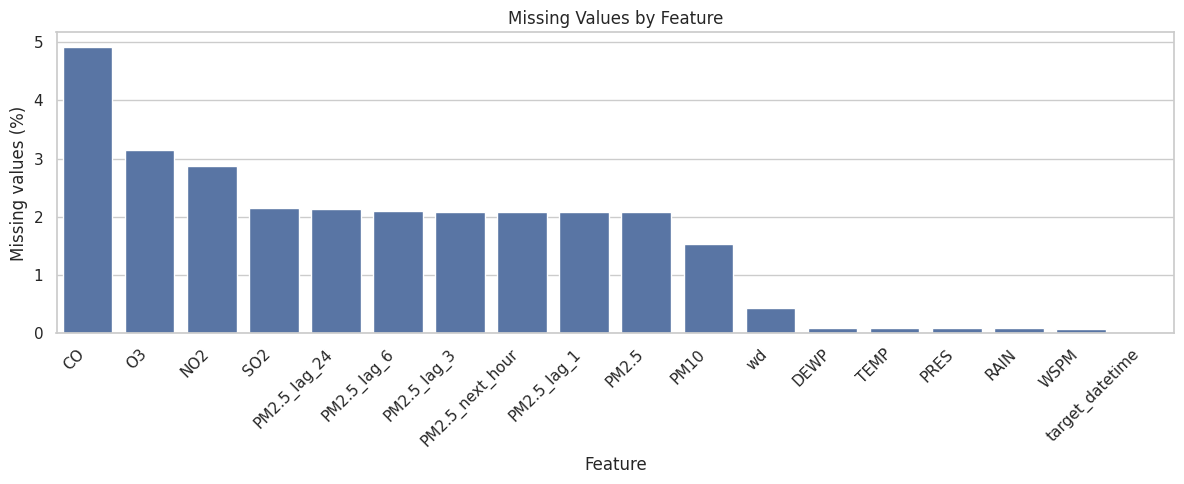

,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,datetime,target_datetime,PM2.5_next_hour,PM2.5_lag_1,PM2.5_lag_3,PM2.5_lag_6,PM2.5_lag_24,hour_sin,hour_cos,month_sin,month_cos,day_of_week,is_weekend
station,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Aotizhongxin,0.0,0.0,0.0,0.0,2.64,2.05,2.67,2.92,5.07,4.90,0.06,0.06,0.06,0.06,0.23,0.04,0.0,0.0,2.64,2.64,2.65,2.66,2.71,0.0,0.0,0.0,0.0,0.0,0.0
Changping,0.0,0.0,0.0,0.0,2.21,1.66,1.79,1.90,4.34,1.72,0.15,0.14,0.15,0.15,0.40,0.12,0.0,0.0,2.21,2.21,2.22,2.22,2.28,0.0,0.0,0.0,0.0,0.0,0.0
Dingling,0.0,0.0,0.0,0.0,2.22,1.87,2.08,3.52,5.74,3.46,0.15,0.14,0.15,0.15,0.40,0.12,0.0,0.0,2.22,2.22,2.23,2.24,2.29,0.0,0.0,0.0,0.0,0.0,0.0
Dongsi,0.0,0.0,0.0,0.0,2.14,1.58,1.89,4.57,9.12,1.89,0.06,0.06,0.06,0.06,0.22,0.04,0.0,0.0,2.14,2.14,2.15,2.16,2.21,0.0,0.0,0.0,0.0,0.0,0.0
Guanyuan,0.0,0.0,0.0,0.0,1.76,1.22,1.35,1.88,5.00,3.35,0.06,0.06,0.06,0.06,0.23,0.04,0.0,0.0,1.76,1.76,1.77,1.77,1.80,0.0,0.0,0.0,0.0,0.0,0.0
Gucheng,0.0,0.0,0.0,0.0,1.84,1.09,1.45,1.91,4.00,2.08,0.15,0.14,0.15,0.12,0.45,0.12,0.0,0.0,1.85,1.85,1.85,1.86,1.91,0.0,0.0,0.0,0.0,0.0,0.0
Huairou,0.0,0.0,0.0,0.0,2.72,2.22,2.79,4.67,4.06,3.28,0.15,0.15,0.15,0.16,0.86,0.14,0.0,0.0,2.72,2.72,2.73,2.73,2.79,0.0,0.0,0.0,0.0,0.0,0.0
Nongzhanguan,0.0,0.0,0.0,0.0,1.79,1.25,1.27,1.97,3.44,1.44,0.06,0.06,0.06,0.06,0.22,0.04,0.0,0.0,1.79,1.79,1.80,1.81,1.85,0.0,0.0,0.0,0.0,0.0,0.0
Shunyi,0.0,0.0,0.0,0.0,2.60,1.56,3.70,3.89,6.21,4.25,0.15,0.15,0.15,0.15,1.38,0.13,0.0,0.0,2.61,2.61,2.61,2.62,2.67,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": air_df.isna().sum(),
    "Missing Percentage": air_df.isna().mean() * 100,
}).sort_values("Missing Percentage", ascending=False)
display(missing_summary.round(2))

missing_features = missing_summary[missing_summary["Missing Count"] > 0]
if not missing_features.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(data=missing_features.reset_index(names="Feature"), x="Feature", y="Missing Percentage")
    plt.title("Missing Values by Feature")
    plt.ylabel("Missing values (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

missing_by_station = air_df.groupby("station").apply(
    lambda g: g.isna().mean() * 100, include_groups=False
)
display(missing_by_station.round(2))

## 6. Exploratory data analysis (EDA)

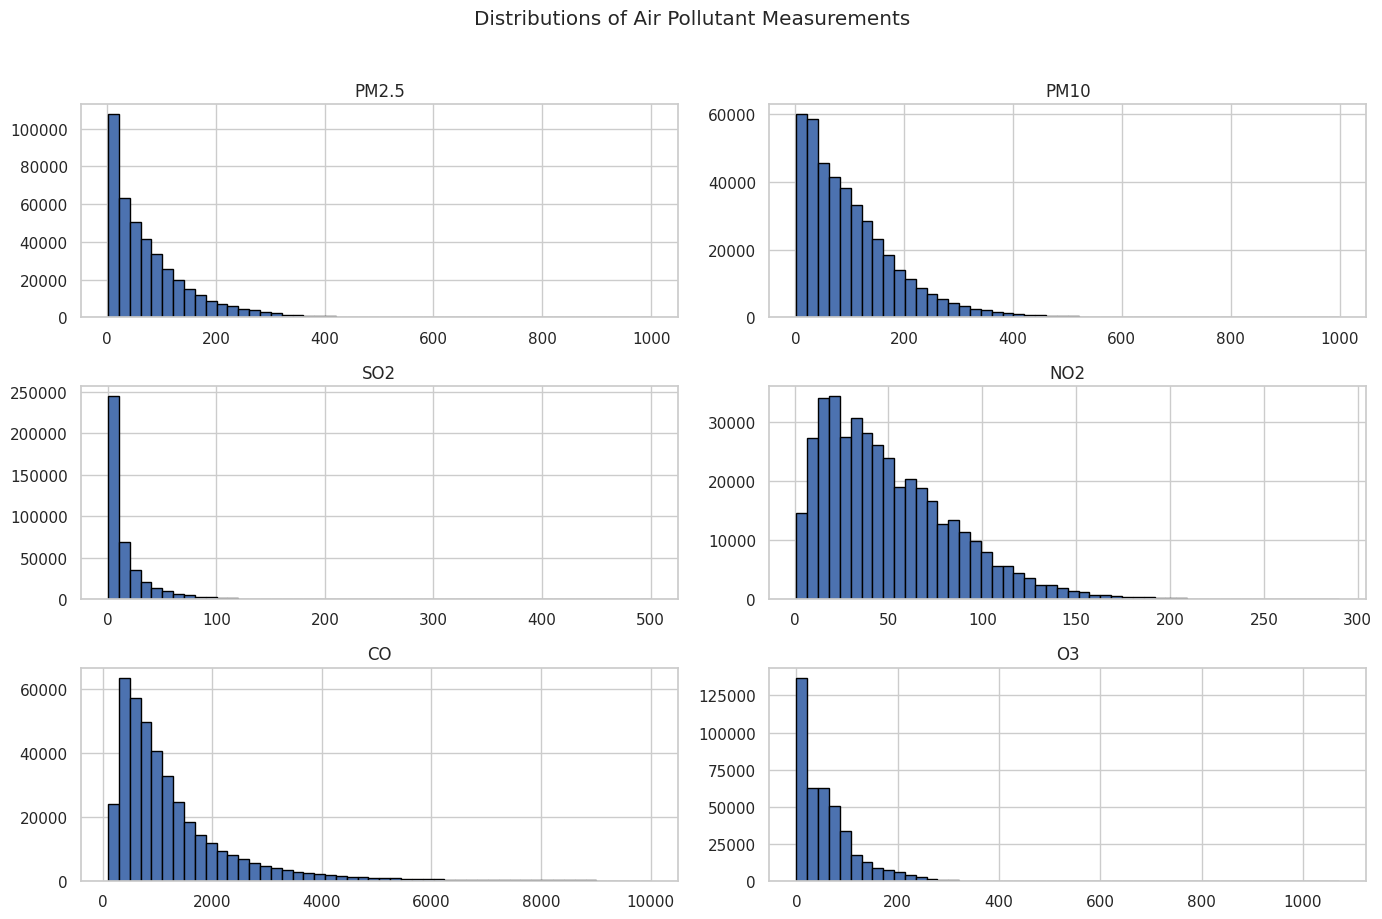

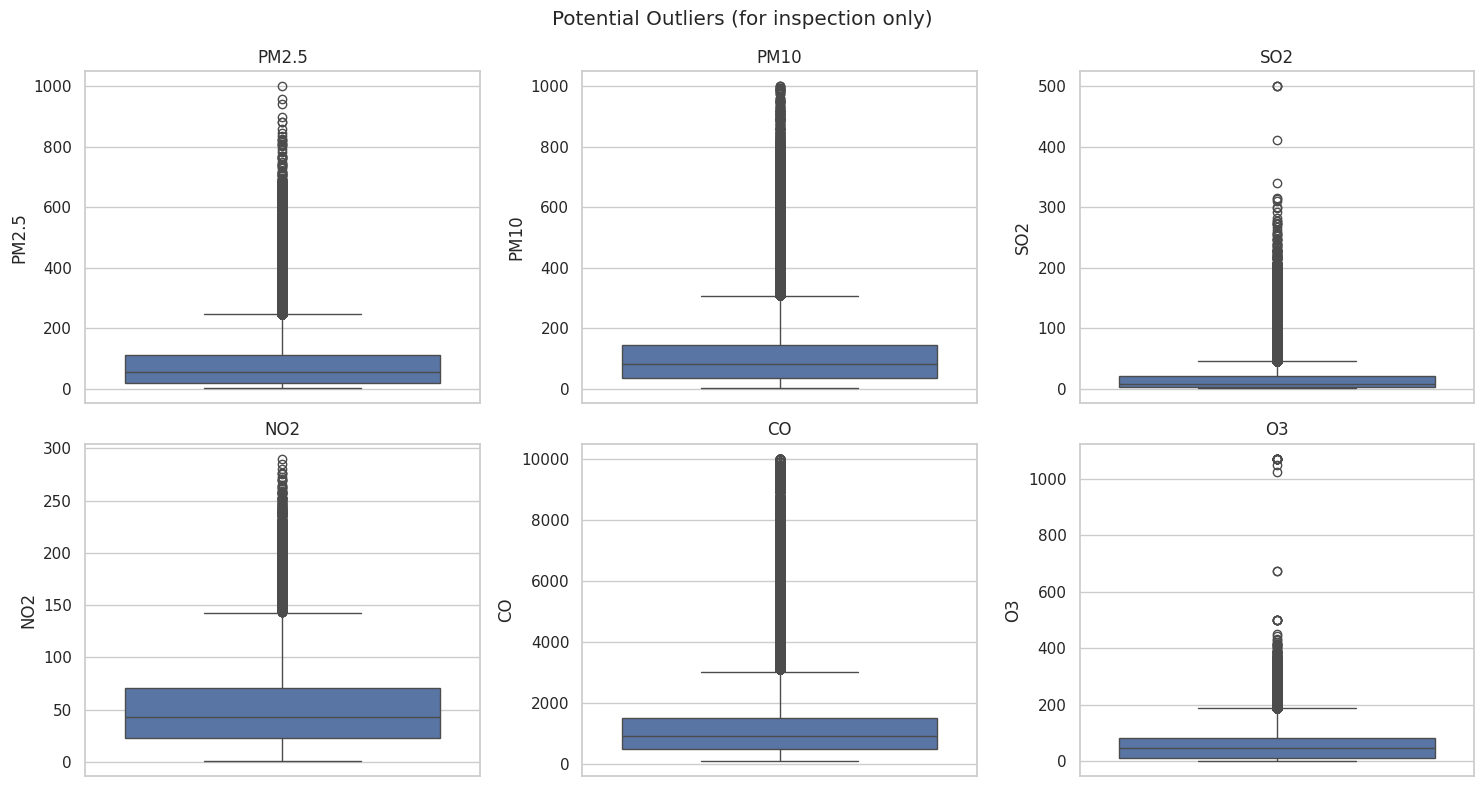

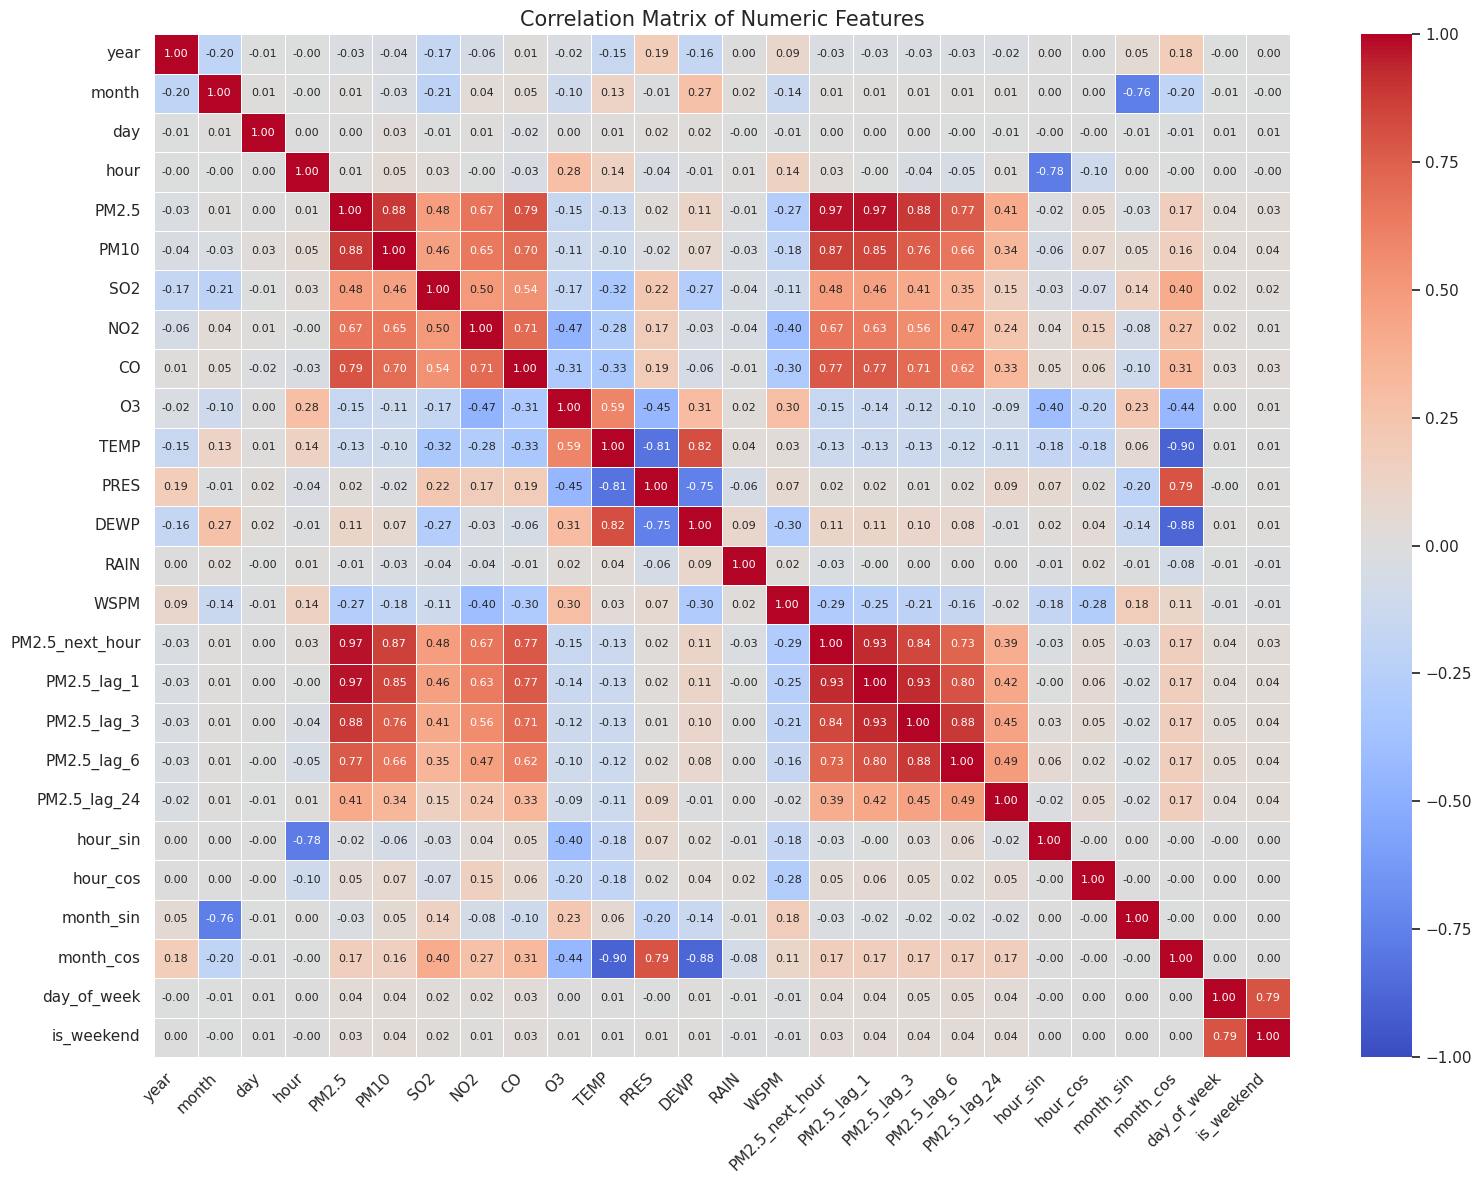

Correlation with PM2.5:


,correlation
PM2.5,1.000
PM2.5_lag_1,0.969
PM2.5_next_hour,0.969
PM10,0.884
PM2.5_lag_3,0.884
CO,0.790
PM2.5_lag_6,0.767
NO2,0.667
SO2,0.482
PM2.5_lag_24,0.408


In [ ]:
pollutants = [
    c for c in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
    if c in air_df.columns
]

# 1. Pollutant distributions
if pollutants:
    air_df[pollutants].hist(
        figsize=(14, 9),
        bins=50,
        edgecolor="black"
    )

    plt.suptitle(
        "Distributions of Air Pollutant Measurements",
        y=1.02
    )
    plt.tight_layout()
    plt.show()

    # 2. Boxplots for outlier inspection
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))

    for ax, col in zip(axes.flat, pollutants):
        sns.boxplot(y=air_df[col], ax=ax)
        ax.set_title(col)

    for ax in axes.flat[len(pollutants):]:
        ax.remove()

    plt.suptitle("Potential Outliers (for inspection only)")
    plt.tight_layout()
    plt.show()

# 3. Correlation matrix with values in each cell
numeric_df = air_df.select_dtypes(include=np.number)
corr_matrix = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,              # Show values in each cell
    fmt=".2f",               # Two decimal places
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title("Correlation Matrix of Numeric Features", fontsize=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Features correlated with PM2.5
if "PM2.5" in numeric_df.columns:
    print("Correlation with PM2.5:")

    display(
        corr_matrix["PM2.5"]
        .sort_values(ascending=False)
        .to_frame("correlation")
        .round(3)
    )

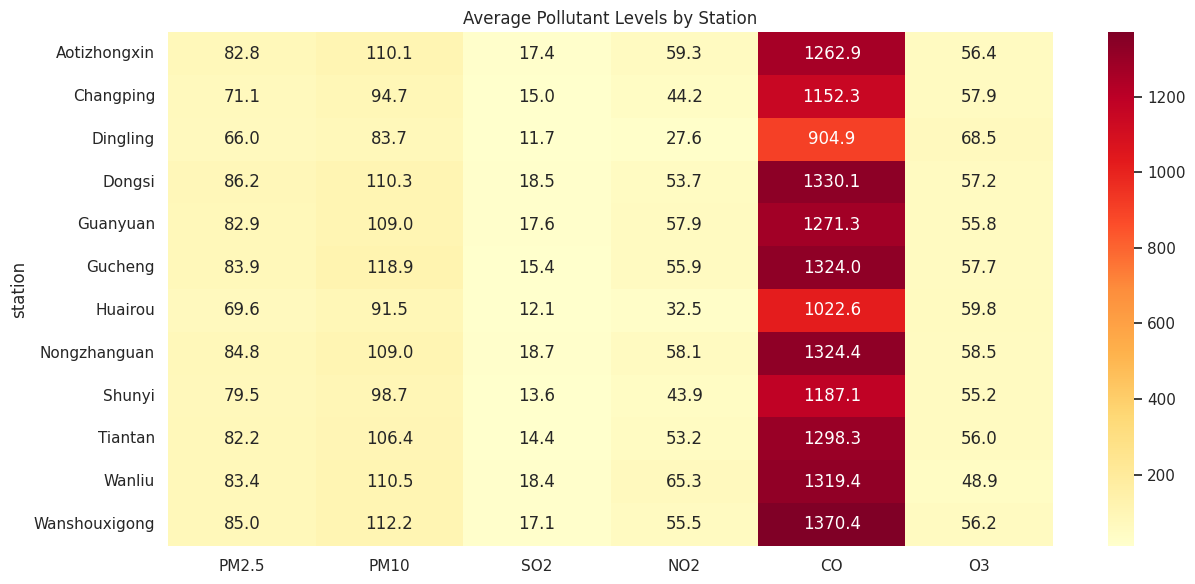

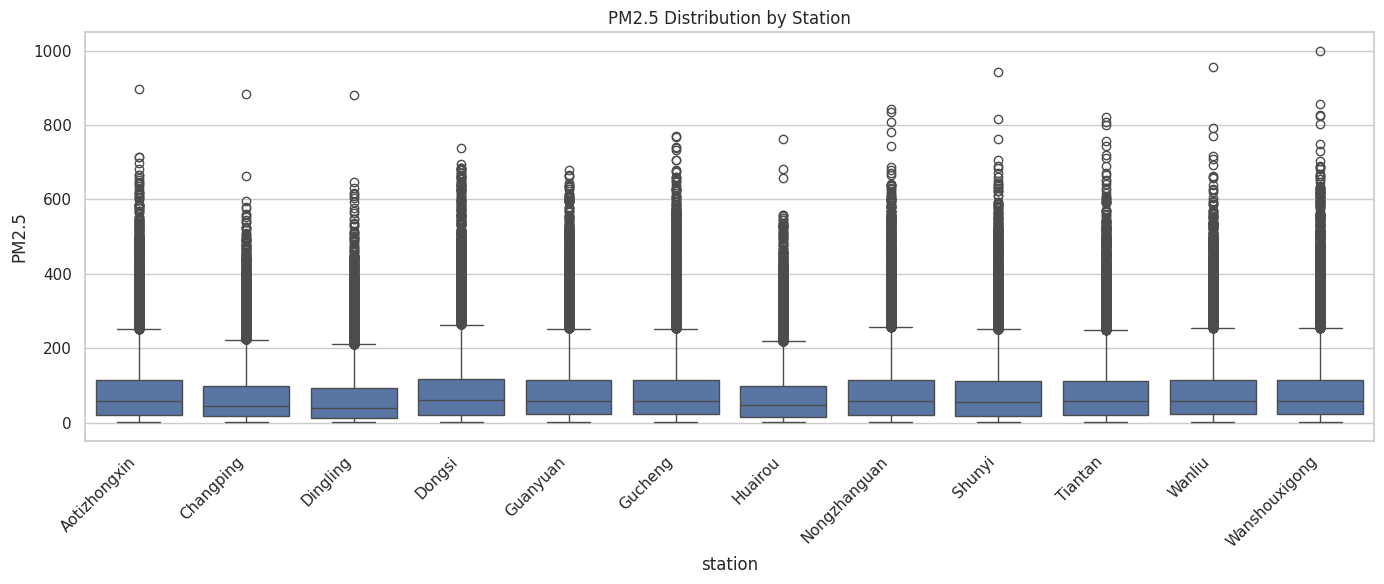

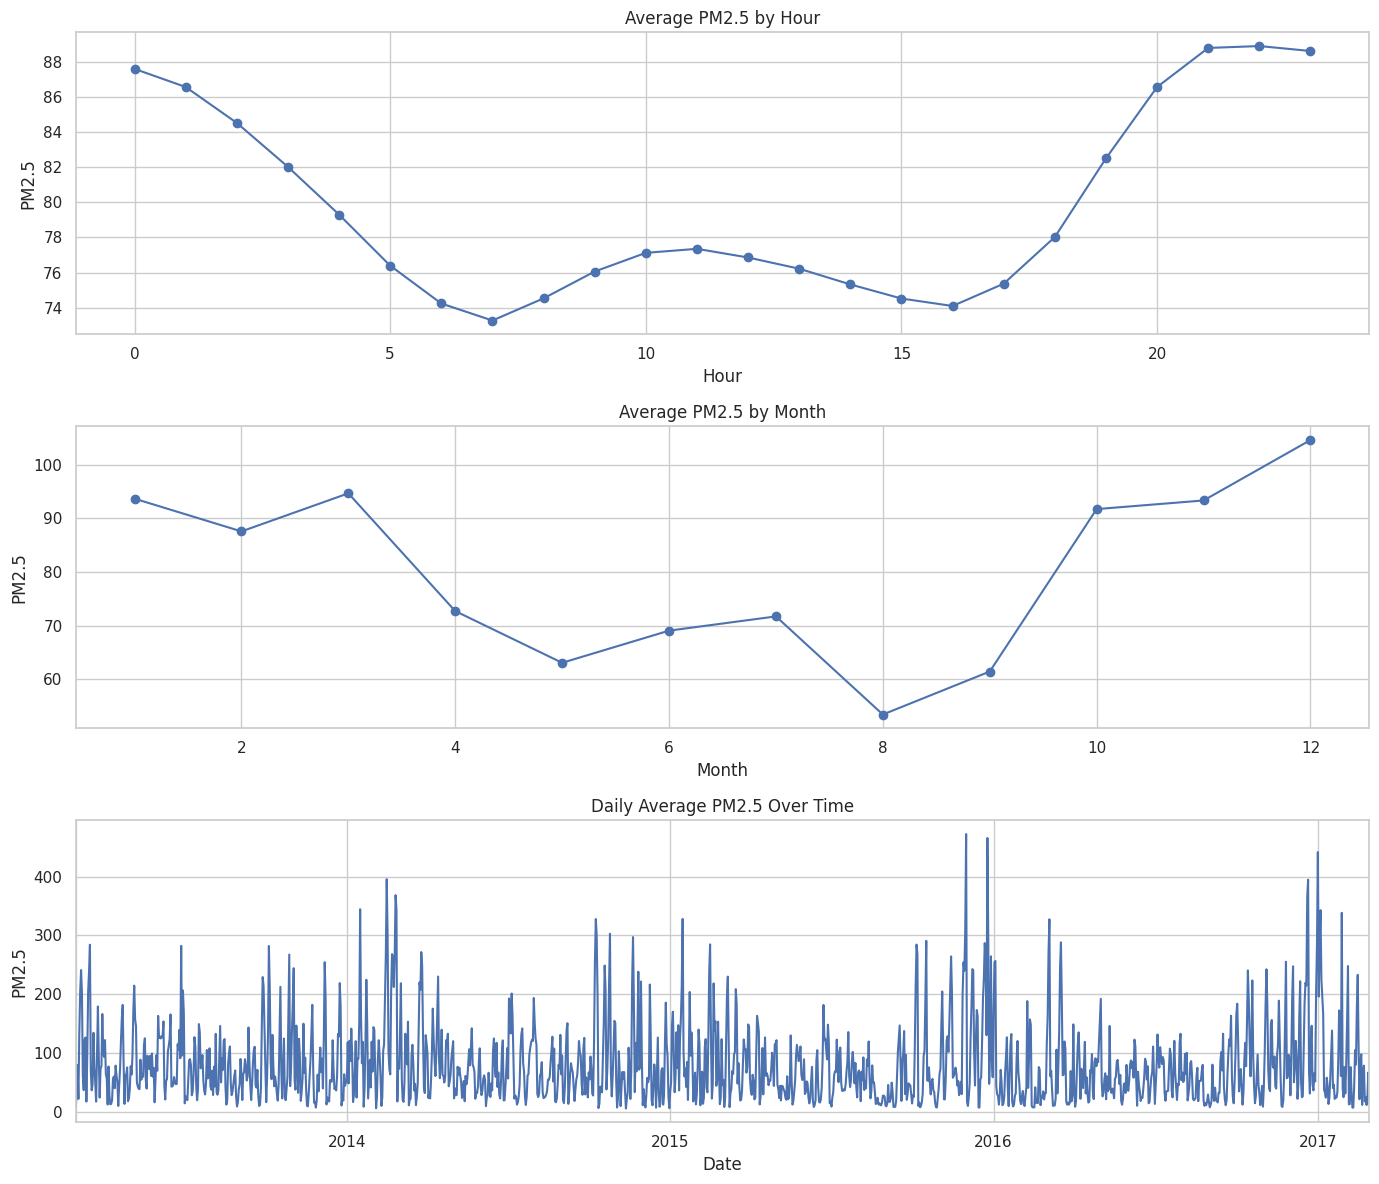

In [ ]:
# Station-level pollutant averages
if pollutants:
    station_means = air_df.groupby("station")[pollutants].mean()
    plt.figure(figsize=(13, 6))
    sns.heatmap(station_means, cmap="YlOrRd", annot=True, fmt=".1f")
    plt.title("Average Pollutant Levels by Station")
    plt.tight_layout()
    plt.show()

if "PM2.5" in air_df.columns:
    plt.figure(figsize=(14, 6))
    sns.boxplot(data=air_df, x="station", y="PM2.5")
    plt.title("PM2.5 Distribution by Station")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    hourly_pm25 = air_df.groupby("hour")["PM2.5"].mean()
    monthly_pm25 = air_df.groupby("month")["PM2.5"].mean().reindex(range(1, 13))
    daily_pm25 = air_df.groupby(air_df["datetime"].dt.floor("D"))["PM2.5"].mean()

    fig, axes = plt.subplots(3, 1, figsize=(14, 12))
    hourly_pm25.plot(ax=axes[0], marker="o")
    axes[0].set(title="Average PM2.5 by Hour", xlabel="Hour", ylabel="PM2.5")
    monthly_pm25.plot(ax=axes[1], marker="o")
    axes[1].set(title="Average PM2.5 by Month", xlabel="Month", ylabel="PM2.5")
    daily_pm25.plot(ax=axes[2])
    axes[2].set(title="Daily Average PM2.5 Over Time", xlabel="Date", ylabel="PM2.5")
    plt.tight_layout()
    plt.show()

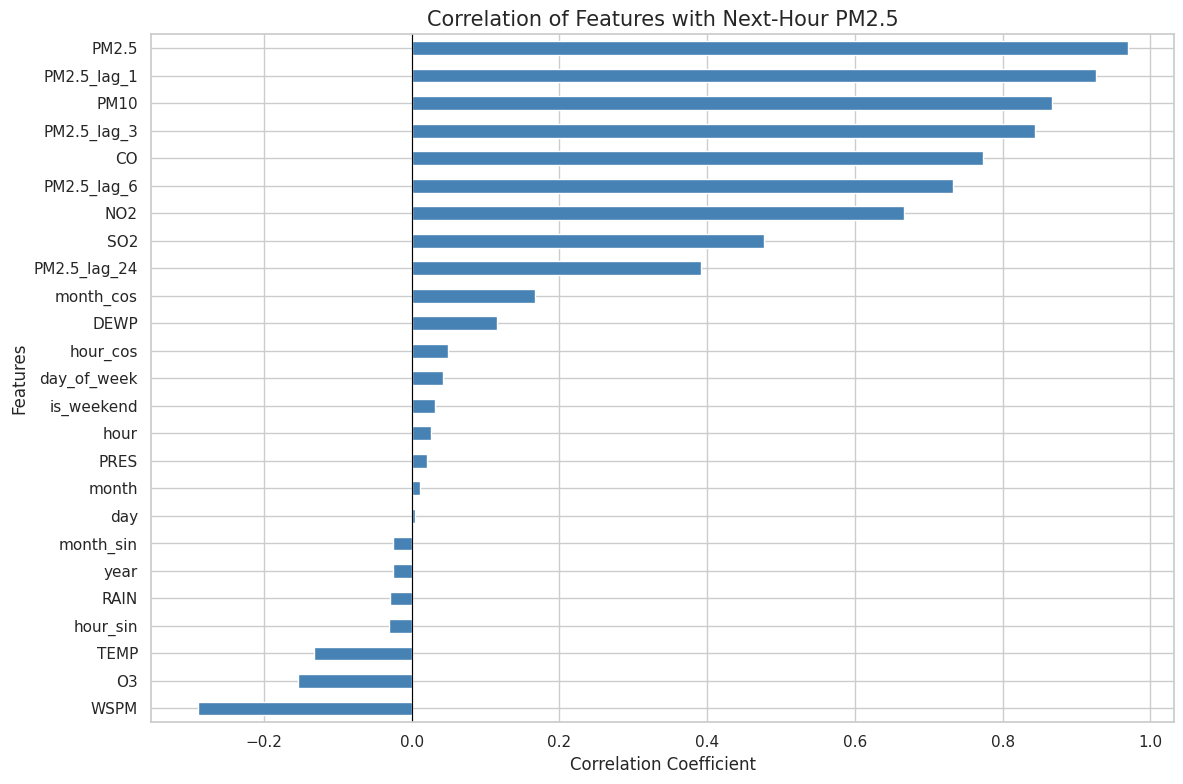

In [ ]:
# 2. Correlation Bar Chart

target = "PM2.5_next_hour"

# Calculate correlation with target
target_correlation = (
    model_df.select_dtypes(include=["number"])
    .corr()[target]
    .drop(target)
    .dropna()
    .sort_values()
)

# Plot bar chart
plt.figure(figsize=(12, 8))

target_correlation.plot(
    kind="barh",
    color="steelblue"
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("Correlation of Features with Next-Hour PM2.5", fontsize=15)
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

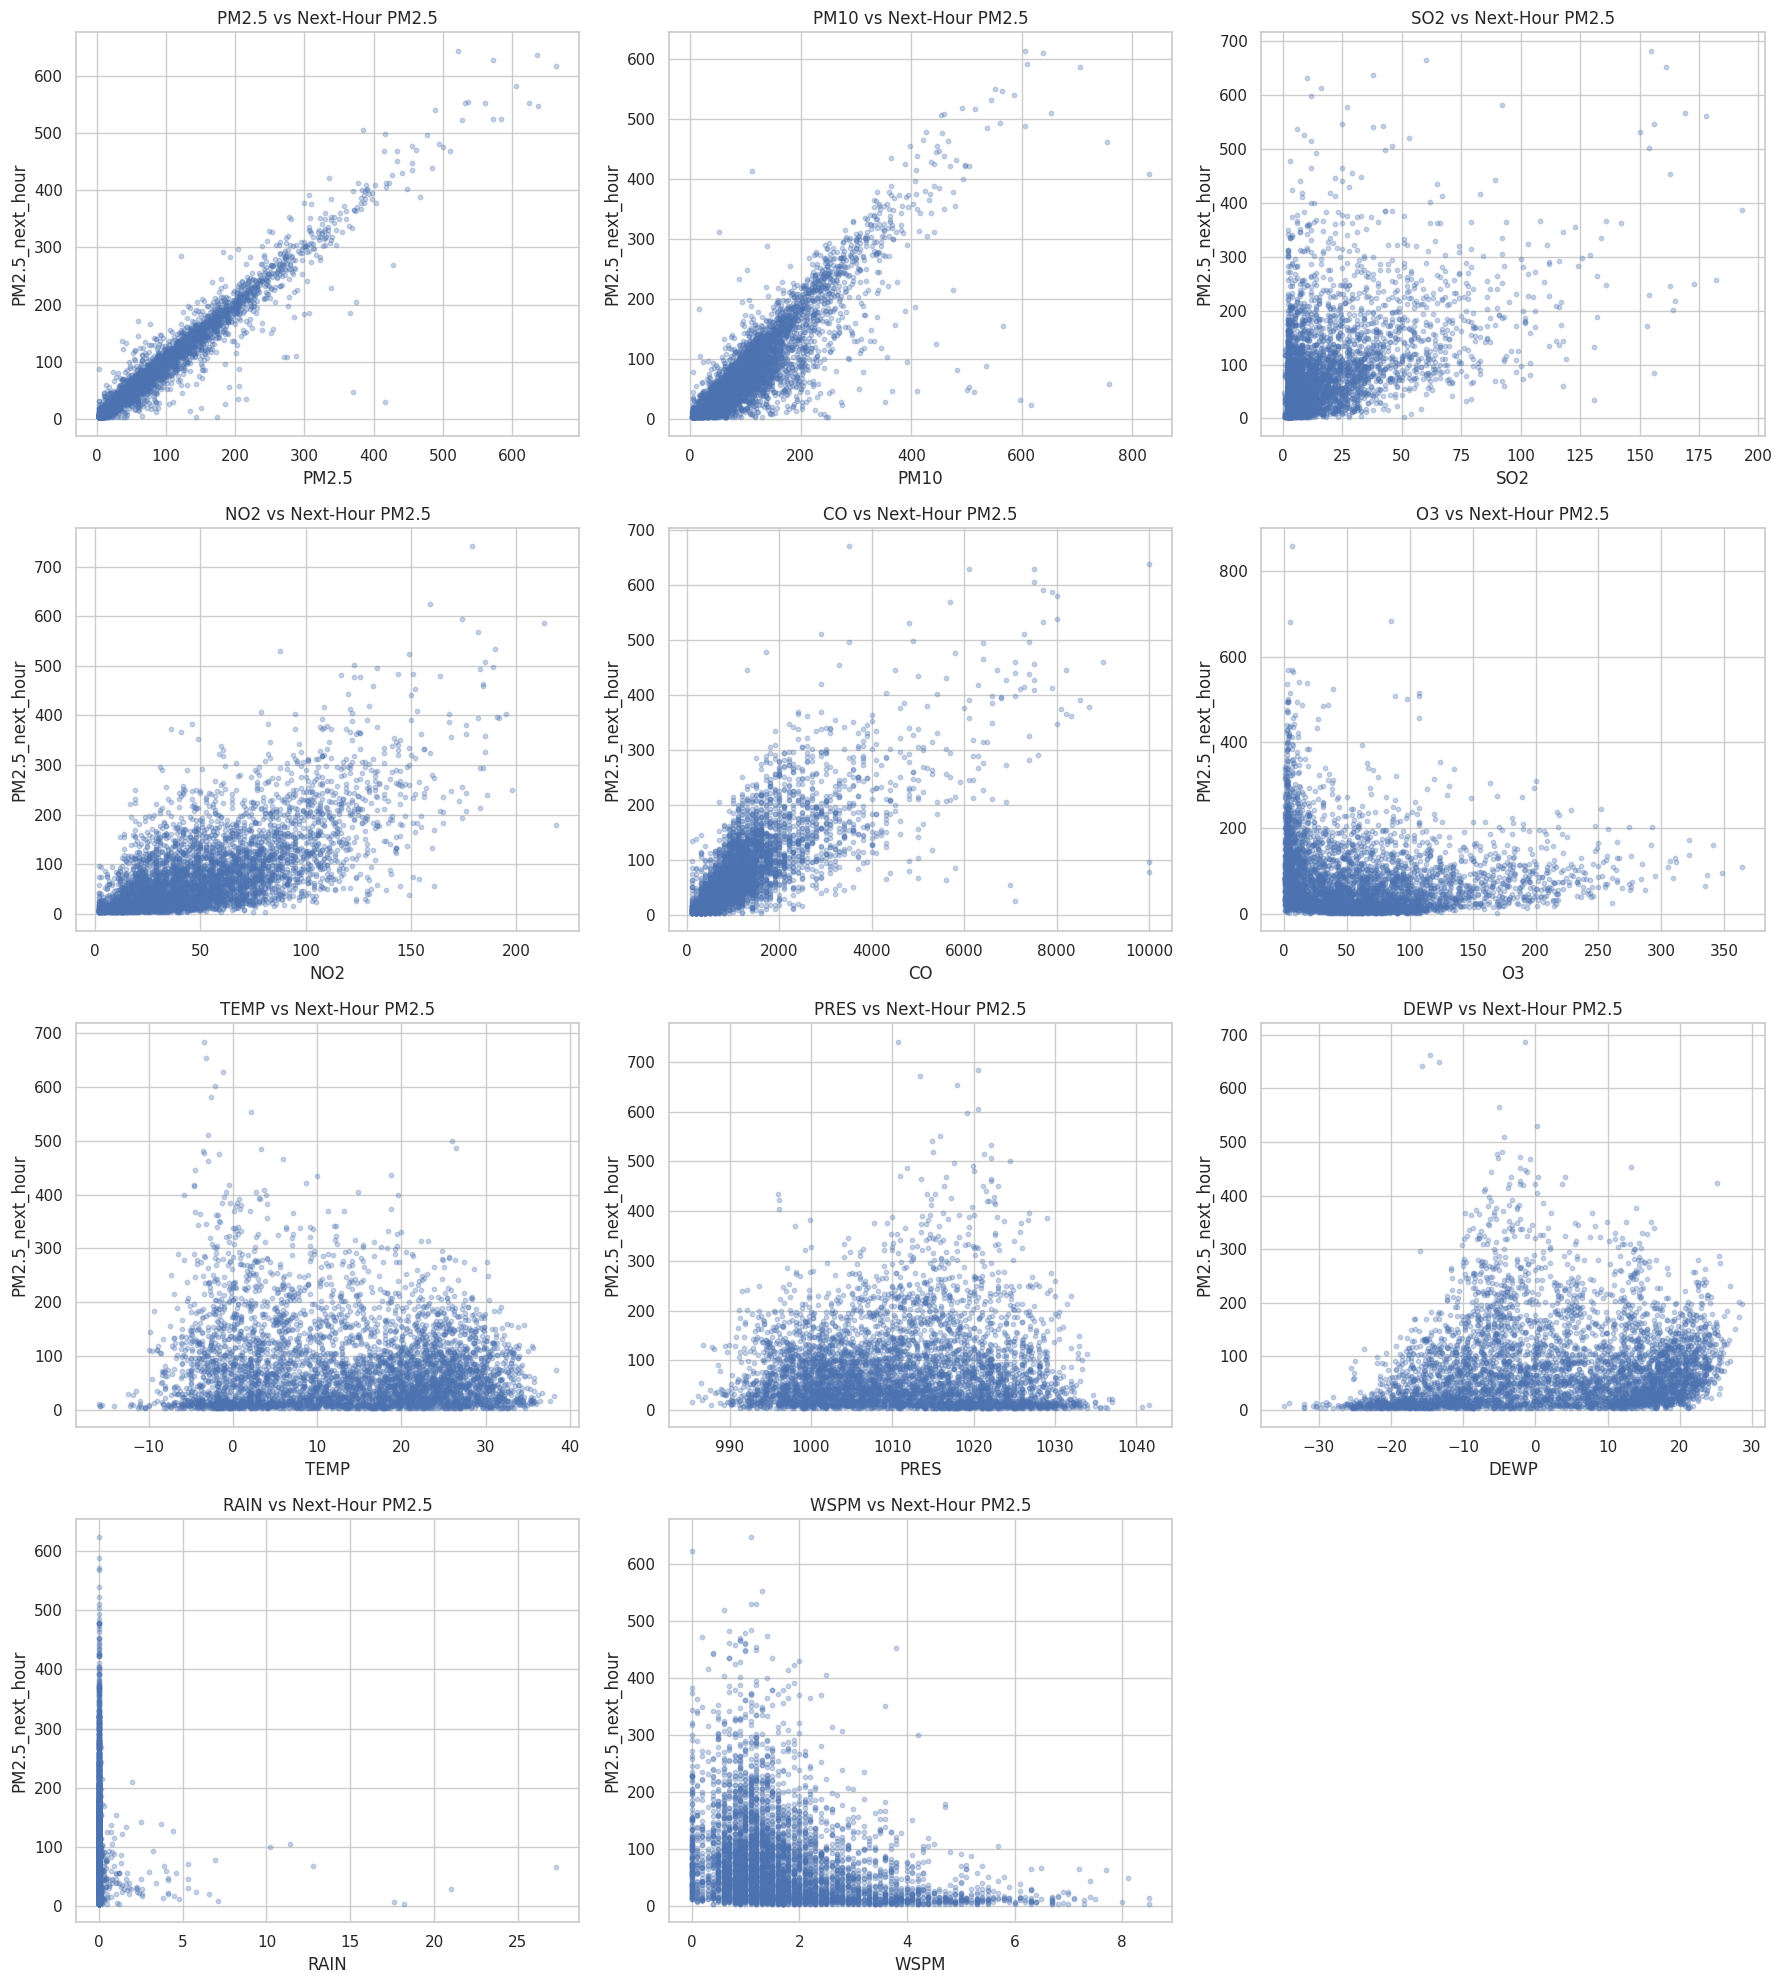

In [ ]:
# 3. Scatter Plots

target = "PM2.5_next_hour"

features = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM"
]

# Keep only features available in model_df
features = [col for col in features if col in model_df.columns]

# Create subplots
fig, axes = plt.subplots(4, 3, figsize=(18, 20))

axes = axes.flatten()

for i, feature in enumerate(features):

    plot_data = model_df[[feature, target]].dropna()

    # Sample rows to make plotting faster
    if len(plot_data) > 5000:
        plot_data = plot_data.sample(n=5000, random_state=42)

    axes[i].scatter(
        plot_data[feature],
        plot_data[target],
        alpha=0.3,
        s=10
    )

    axes[i].set_title(f"{feature} vs Next-Hour PM2.5")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel(target)

# Remove unused subplots
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

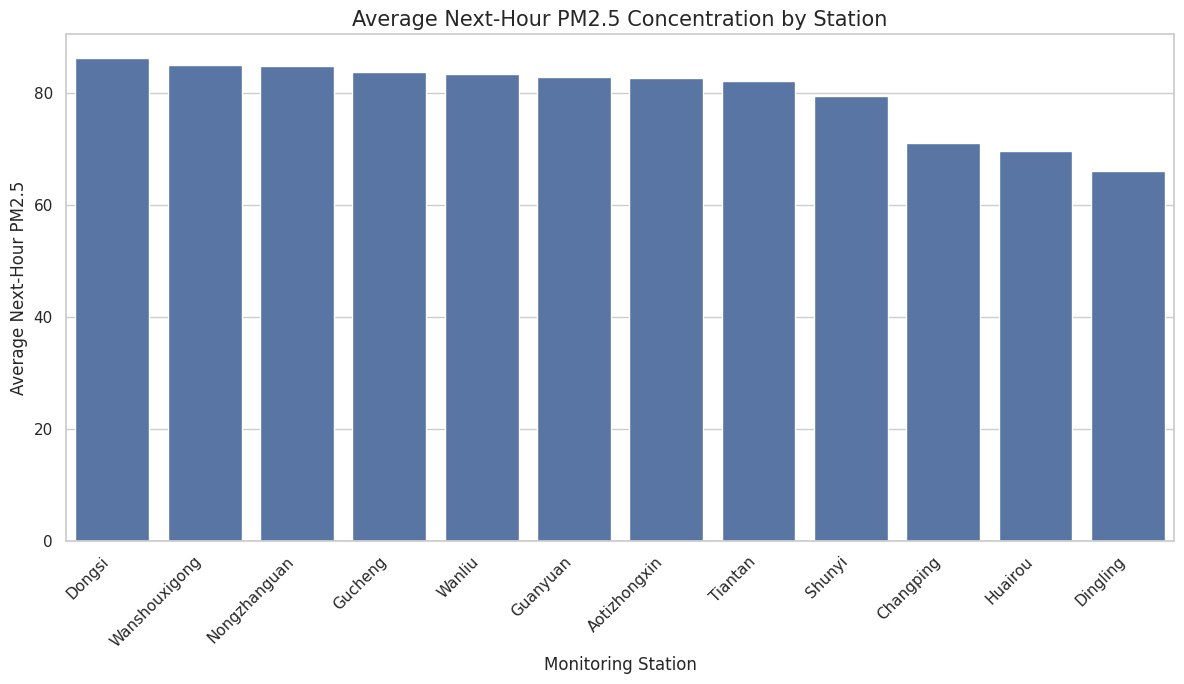

In [ ]:
# 4. Station-wise Comparison

station_average = (
    model_df.groupby("station")["PM2.5_next_hour"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=station_average.index,
    y=station_average.values
)

plt.title("Average Next-Hour PM2.5 Concentration by Station", fontsize=15)
plt.xlabel("Monitoring Station")
plt.ylabel("Average Next-Hour PM2.5")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()